# Lunar-HFE, part 3: the Supporting Information

This notebook reads the results in `code/results/` (shipped with the repository,
or recomputed by `1_run_analysis.ipynb`), puts every number printed in the 14
tables of the Supporting Information next to the value the results give, and
draws SI Figures S5–S7. It recomputes nothing: **Run All**, a few minutes.

In [1]:
try:
    from lunar import notebook as nb
except ImportError:
    raise ImportError("The lunar package is not installed. In a terminal, in the repository folder, run:\n"
                      "    pip install -e \".[dev,mcmc]\"\nthen restart the kernel.")
import numpy as np
import pandas as pd
from IPython.display import display
nb.set_mode("show")          # this notebook reads the results; it recomputes nothing
S2 = ("A15", "A17")
import sys
for _p in ("pipeline/figures", "pipeline/compute", "."):          # the scripts some checks reuse
    if str(nb.CODE / _p) not in sys.path:
        sys.path.insert(0, str(nb.CODE / _p))
from lunar.apollo_helpers import extract_sensor_stability

# SI Figures S5-S7, drawn from the results (about a minute)
nb.figures("figures/make_joint_figures.py", makes=("fig_joint_annual_wave", "fig_joint_mcmc", "fig_joint_variants"),
           minutes=1, args=("--only", "annual_wave,mcmc,variants"), always=True)

Run mode: 'show'. Nothing is recomputed; every step shows its stored result.
▶ make_joint_figures.py: making figures (about 1 min)


excess data in 'kern' subtable: 6 bytes


excess data in 'kern' subtable: 6 bytes


excess data in 'kern' subtable: 6 bytes


excess data in 'kern' subtable: 6 bytes


...

excess data in 'kern' subtable: 6 bytes


  -> figures/fig_joint_annual_wave.pdf


Ensuring Apollo HFE (a15) ...


Ensuring Apollo HFE (a17) ...


--- make_joint_figures.py finished in 9 s


In [2]:
R = {n: nb.load(f"{n}.json") for n in (
    "stability_windows", "joint_albedo_fit", "joint_fit_checks", "joint_fit_sensitivities",
    "joint_numerics_certification", "likelihood_ratio", "gradient_epochs", "albedo_sensitivity",
    "albedo_anchor", "joint_probe_checks", "joint_valley", "joint_block_bootstrap", "annual_wave",
    "annual_wave_surface_test", "own_diffusivity_fit", "transient_warming", "joint_mcmc", "joint_chi_density",
    "subset_fits")}
JF, FC, LR, GE = R["joint_albedo_fit"], R["joint_fit_checks"], R["likelihood_ratio"], R["gradient_epochs"]
best = {s: JF["sites"][s]["with_diffusivity"]["best"] for s in S2}
print("results loaded:", ", ".join(R))

results loaded: stability_windows, joint_albedo_fit, joint_fit_checks, joint_fit_sensitivities, joint_numerics_certification, likelihood_ratio, gradient_epochs, albedo_sensitivity, albedo_anchor, joint_probe_checks, joint_valley, joint_block_bootstrap, annual_wave, annual_wave_surface_test, own_diffusivity_fit, transient_warming, joint_mcmc, joint_chi_density, subset_fits


---
# The Supporting Information, table by table

Every number printed in the 14 tables of the Supporting Information, cell by
cell, next to the value in `code/results/` rounded the way the SI rounds it.
The printed values are typed in below as they appear in the SI.

In [3]:
for n in ("martinez_density_fit", "joint_diviner", "cpp_benchmark", "joint_numerics_certification"):
    R.setdefault(n, nb.load(f"{n}.json"))
def sg(v, fmt=".2f"):
    """Signed as the SI prints it: +1.35, -0.02, and 0.00 (no sign) when it rounds to zero."""
    s = nb.rounded(v, fmt)
    return s if float(s) == 0 or s.startswith("-") else "+" + s
def cells(chk, label, names, shown, paper):
    """One check per printed cell."""
    assert len(names) == len(shown) == len(paper), label
    for n, a, b in zip(names, shown, paper):
        chk.add_text(f"{label}: {n}", a, b)

**SI Table S1, stability windows** (`stability_windows.json`).

In [4]:
S1 = """
A15 1 TG11B 84 fallback 1975-05-01 1975-06-30 11579 253.20 0.05 +0.13
A15 2 TR22B 87 fallback 1973-12-12 1974-12-27 153 250.88 0.09 +0.19
A15 1 TG12A 91 strict 1974-04-09 1975-06-30 20883 253.15 0.04 +0.03
A15 2 TG22B 97 strict 1974-05-11 1975-06-30 20432 251.16 0.05 +0.08
A15 1 TR12A 101 fallback 1973-12-03 1974-12-27 153 253.14 0.07 +0.22
A15 1 TR12B 129 fallback 1973-12-03 1974-12-27 153 253.36 0.06 +0.19
A15 1 TG12B 139 strict 1974-04-09 1975-06-30 20883 253.53 0.03 +0.07
A17 1 TG11A 130 fallback 1977-05-21 1977-09-30 23969 256.48 0.04 +0.32
A17 2 TG21A 131 fallback 1977-05-21 1977-09-30 23917 256.59 0.04 +0.22
A17 1 TR11A 140 fallback 1974-06-03 1974-12-27 79 255.67 0.08 +0.47
A17 2 TR21A 140 fallback 1974-06-05 1974-12-27 79 256.24 0.04 +0.23
A17 1 TR11B 167 fallback 1974-06-03 1974-12-27 79 255.88 0.06 +0.33
A17 2 TR21B 169 fallback 1974-06-05 1974-12-27 79 256.38 0.03 +0.15
A17 1 TG11B 177 fallback 1977-05-21 1977-09-30 23969 256.60 0.03 +0.22
A17 2 TG21B 178 fallback 1977-05-21 1977-09-30 23917 256.74 0.03 +0.11
A17 1 TG12A 185 fallback 1974-05-28 1974-12-31 5148 256.06 0.05 +0.22
A17 2 TG22A 186 strict 1973-12-18 1974-12-31 9239 256.52 0.03 +0.06
A17 1 TR12A 195 fallback 1974-05-24 1974-12-27 82 256.13 0.04 +0.18
A17 2 TR22A 196 strict 1974-01-02 1974-12-27 141 256.55 0.02 +0.06
A17 1 TR12B 223 strict 1973-12-14 1974-12-27 147 256.38 0.03 +0.07
A17 2 TR22B 224 strict 1974-01-02 1974-12-27 141 256.74 0.02 +0.03
A17 1 TG12B 233 strict 1973-12-18 1974-12-31 9267 256.48 0.03 +0.06
A17 2 TG22B 234 strict 1973-12-18 1974-12-31 9239 256.84 0.03 +0.01"""
chk = nb.Checks("SI Table S1, stability windows:")
used = {s: [r for r in R["stability_windows"][s] if r["used"]] for s in S2}
printed = [l.split() for l in S1.strip().splitlines()]
for s in S2:   # the table lists every used sensor, by depth
    chk.add_text(f"{s}: sensors listed, in depth order", " ".join(r["sensor"] for r in sorted(used[s], key=lambda r: r["depth_cm"])),
                 " ".join(p[2] for p in printed if p[0] == s))
for p in printed:
    r = next(r for r in used[p[0]] if r["sensor"] == p[2])
    crit = {"trend_flat": "strict", "fallback_last25": "fallback"}[r["method"]]
    cells(chk, f"{p[0]} {p[2]}", ["probe", "depth", "criterion", "first date", "last date", "N", "T_eq", "sigma", "slope"],
          [str(r["probe"]), f'{r["depth_cm"]:.0f}', crit, r["window_start"], r["window_end"], str(r["n_samples"]),
           nb.rounded(r["T_eq_K"], ".2f"), nb.rounded(r["T_std_K"], ".2f"), sg(r["trailing_slope_K_per_yr"])], p[1:2] + p[3:])
chk.show()

SI Table S1, stability windows:


quantity,this repository,paper,match
"A15: sensors listed, in depth order",TG11B TR22B TG12A TG22B TR12A TR12B TG12B,TG11B TR22B TG12A TG22B TR12A TR12B TG12B,✓
"A17: sensors listed, in depth order",TG11A TG21A TR11A TR21A TR11B TR21B TG11B TG21B TG12A TG22A TR12A TR22A TR12B TR22B TG12B TG22B,TG11A TG21A TR11A TR21A TR11B TR21B TG11B TG21B TG12A TG22A TR12A TR22A TR12B TR22B TG12B TG22B,✓
A15 TG11B: probe,1,1,✓
A15 TG11B: depth,84,84,✓
A15 TG11B: criterion,fallback,fallback,✓
A15 TG11B: first date,1975-05-01,1975-05-01,✓
A15 TG11B: last date,1975-06-30,1975-06-30,✓
A15 TG11B: N,11579,11579,✓
A15 TG11B: T_eq,253.20,253.20,✓
A15 TG11B: sigma,0.05,0.05,✓


All values match the paper.


True

**SI Table S2, measured and modeled gradients** (`gradient_epochs.json`).

In [5]:
chk = nb.Checks("SI Table S2, gradients:")
G = R["gradient_epochs"]["sites"]
for key, a15, a17, qb in (("certified", ("2.54", "2.02"), ("0.37", "0.23"), "3.6"),
                          ("common_1974", ("2.63", "1.99"), ("0.81", "0.20"), "9.5"),
                          ("translated_1974", ("2.59", "2.00"), ("0.89", "0.18"), "10.5"),
                          ("thermoluminescence", None, ("1.0", "0.5"), "12.0")):
    for s, pr in (("A15", a15), ("A17", a17)):
        if pr is None:
            continue
        o = G[s]["observed"][key]; f = ".1f" if key == "thermoluminescence" else ".2f"
        cells(chk, f"{key}, {s}", ["gradient", "standard error"], [nb.rounded(o["gradient_K_per_m"], f), nb.rounded(o["se"], f)], list(pr))
    chk.add(f"{key}: Q_b matching the A17 gradient", G["A17"]["observed"][key]["qb_matching_mW"], qb, ".1f")
for key, a15, a17 in (("joint_fit", "2.14", "1.32"), ("global_3p4", "3.06", "2.28"), ("martinez", "2.66", "1.99")):
    cells(chk, f"model, {key}", ["A15", "A17"], [nb.rounded(G[s]["model_gradient_K_per_m"][key], ".2f") for s in S2], [a15, a17])
chk.show()

SI Table S2, gradients:


quantity,this repository,paper,match
"certified, A15: gradient",2.54,2.54,✓
"certified, A15: standard error",2.02,2.02,✓
"certified, A17: gradient",0.37,0.37,✓
"certified, A17: standard error",0.23,0.23,✓
certified: Q_b matching the A17 gradient,3.6,3.6,✓
"common_1974, A15: gradient",2.63,2.63,✓
"common_1974, A15: standard error",1.99,1.99,✓
"common_1974, A17: gradient",0.81,0.81,✓
"common_1974, A17: standard error",0.20,0.20,✓
common_1974: Q_b matching the A17 gradient,9.5,9.5,✓


All values match the paper.


True

**SI Table S9, the ±5 K test of Hayne et al. (2017)** (`joint_probe_checks.json`).

In [6]:
S9 = {"A15": [("1.25", "209.6", "256.0", "yes"), ("3.4", "212.8", "253.4", "yes"), ("5.00", "214.5", "253.5", "yes"),
              ("6.50", "215.9", "253.8", "yes"), ("10.25", "218.7", "254.6", "no")],
      "A17": [("1.25", "211.7", "260.6", "yes"), ("3.4", "214.9", "257.2", "yes"), ("5.00", "216.7", "257.1", "yes"),
              ("6.50", "218.1", "257.3", "yes"), ("10.25", "220.9", "258.0", "yes")]}
chk = nb.Checks("SI Table S9, the +-5 K test at A = 0.12:")
for s in S2:
    kt = R["joint_probe_checks"]["sites"][s]["keihm_test_values_A_0.12"]
    chk.add(f"{s}: target surface mean", kt["surface_obs_K"], {"A15": "211", "A17": "216"}[s], ".0f")
    chk.add(f"{s}: target deep temperature", kt["deep_obs_K"], {"A15": "252", "A17": "256"}[s], ".0f")
    for r, p in zip(kt["rows"], S9[s]):
        kd = p[0]
        cells(chk, f"{s}, K_d {kd}", ["K_d", "surface mean", "deep temperature", "passes"],
              [nb.rounded(r["kd_mW"], ".1f" if kd == "3.4" else ".2f"), nb.rounded(r["surface_K"], ".1f"), nb.rounded(r["deep_K"], ".1f"),
               "yes" if r["passes"] else "no"], list(p))
for s, hi in (("A15", "6.5"), ("A17", "10.3")):
    k = R["joint_probe_checks"]["sites"][s]["keihm_test_A_0.12"]["kd_pass_mW"]
    cells(chk, f"{s}: every K_d that passes", ["from", "to"], [nb.rounded(k[0], ".1f"), nb.rounded(k[1], ".1f")], ["1.3", hi])
chk.show()

SI Table S9, the +-5 K test at A = 0.12:


quantity,this repository,paper,match
A15: target surface mean,211,211,✓
A15: target deep temperature,252,252,✓
"A15, K_d 1.25: K_d",1.25,1.25,✓
"A15, K_d 1.25: surface mean",209.6,209.6,✓
"A15, K_d 1.25: deep temperature",256.0,256.0,✓
"A15, K_d 1.25: passes",yes,yes,✓
"A15, K_d 3.4: K_d",3.4,3.4,✓
"A15, K_d 3.4: surface mean",212.8,212.8,✓
"A15, K_d 3.4: deep temperature",253.4,253.4,✓
"A15, K_d 3.4: passes",yes,yes,✓


All values match the paper.


True

**SI Table S10, the effect of the diffusivity at Apollo 17** (`joint_valley.json`).

In [7]:
S10 = [("3.4", "0.87", "0.57", "0.57", "-5.4", "-3.9", "+22.9", "+42.9", "+65.8"),
       ("5.0", "0.49", "0.83", "0.83", "-2.1", "-0.6", "+4.8", "+2.6", "+7.4"),
       ("6.0", "0.43", "1.00", "1.00", "0.0", "+1.5", "0.0", "0.0", "0.0"),
       ("7.0", "0.39", "1.16", "1.17", "+2.1", "+3.6", "-2.8", "+14.8", "+11.9"),
       ("8.0", "0.40", "1.33", "1.33", "+4.2", "+5.7", "-1.5", "+47.0", "+45.5"),
       ("10.0", "0.60", "1.67", "1.67", "+8.3", "+9.8", "+11.7", "+164.3", "+176.0")]
v = R["joint_valley"]["A17"]
chk = nb.Checks("SI Table S10, the diffusivity at Apollo 17:")
chk.add("albedo held at", v["A"], "0.137", ".3f")
for r, p in zip(v["rows"], S10):
    cells(chk, f"K_d {p[0]}", ["K_d", "RMSE", "kappa 1", "kappa 2", "misfit 1 (sigma)", "misfit 2 (sigma)", "dJ temperatures", "dJ diffusivity", "dJ"],
          [nb.rounded(r["kd_mW"], ".1f"), nb.rounded(r["sensor_rmse_K"], ".2f"), *(nb.rounded(k, ".2f") for k in r["kappa_model"]),
           *(sg(x, ".1f") for x in r["kappa_sigmas"]), sg(r["dJ_sensors"] + r["dJ_surface"], ".1f"),
           sg(r["dJ_diffusivity"], ".1f"), sg(r["dJ_total"], ".1f")], list(p))
chk.show()

SI Table S10, the diffusivity at Apollo 17:


quantity,this repository,paper,match
albedo held at,0.137,0.137,✓
K_d 3.4: K_d,3.4,3.4,✓
K_d 3.4: RMSE,0.87,0.87,✓
K_d 3.4: kappa 1,0.57,0.57,✓
K_d 3.4: kappa 2,0.57,0.57,✓
K_d 3.4: misfit 1 (sigma),-5.4,-5.4,✓
K_d 3.4: misfit 2 (sigma),-3.9,-3.9,✓
K_d 3.4: dJ temperatures,+22.9,+22.9,✓
K_d 3.4: dJ diffusivity,+42.9,+42.9,✓
K_d 3.4: dJ,+65.8,+65.8,✓


All values match the paper.


True

**SI Table S13, modeled minus Diviner surface temperatures** (`joint_diviner.json`).

In [8]:
S13 = {("A15", "hayne_joint"): "+2.6 +1.4 +3.9 +0.3 -1.9 +1.9", ("A15", "hayne_global_fittedA"): "+0.9 +1.3 +0.5 -1.7 -2.0 -1.5",
       ("A15", "martinez_forward_jointA"): "-0.2 +1.5 -2.0 -3.0 -1.7 -4.0",
       ("A17", "hayne_joint"): "+3.0 +0.6 +5.5 +0.1 -4.3 +3.4", ("A17", "hayne_global_fittedA"): "+0.1 +0.1 +0.1 -3.2 -4.8 -2.0",
       ("A17", "martinez_forward_jointA"): "-0.8 +0.8 -2.4 -4.3 -4.2 -4.4"}
chk = nb.Checks("SI Table S13, Diviner:")
for (s, m), p in S13.items():
    d = R["joint_diviner"][s]["models"][m]
    cells(chk, f"{s} {m}", ["zonal mean", "zonal day", "zonal night", "site mean", "site day", "site night"],
          [sg(d[w][k], ".1f") for w in ("zonal", "site_pm0.5deg") for k in ("bias_K", "bias_day_K", "bias_night_K")], p.split())
chk.show()

SI Table S13, Diviner:


quantity,this repository,paper,match
A15 hayne_joint: zonal mean,+2.6,+2.6,✓
A15 hayne_joint: zonal day,+1.4,+1.4,✓
A15 hayne_joint: zonal night,+3.9,+3.9,✓
A15 hayne_joint: site mean,+0.3,+0.3,✓
A15 hayne_joint: site day,-1.9,-1.9,✓
A15 hayne_joint: site night,+1.9,+1.9,✓
A15 hayne_global_fittedA: zonal mean,+0.9,+0.9,✓
A15 hayne_global_fittedA: zonal day,+1.3,+1.3,✓
A15 hayne_global_fittedA: zonal night,+0.5,+0.5,✓
A15 hayne_global_fittedA: site mean,-1.7,-1.7,✓


All values match the paper.


True

**SI Table S7, temperature-only fits with fixed or published albedos**
(`albedo_sensitivity.json`, `albedo_anchor.json`, `likelihood_ratio.json`).
$K_d$ at the grid edge prints as 27\*; † marks a treatment that matches both
measurements (bias within 1 K, surface mean within 5 K).

In [9]:
S7 = [  # treatment: A0, then K_d, bias, surface mean at A15 and at A17
    ("Constant, lunar average", "0.12", "4.64", "+1.35", "214.2", "5.78", "+1.47", "217.4"),
    ("Constant, site map", "0.109 / 0.095", "4.64", "+2.29", "214.8", "5.66", "+3.54", "218.7"),
    ("Hayne law, map, f=0.25", "0.109 / 0.095", "4.53†", "+0.22", "212.9", "5.74", "+1.68", "217.1"),
    ("Hayne law, map, f=0.5", "0.109 / 0.095", "15.33", "-0.02", "218.4", "8.61†", "+0.04", "217.6"),
    ("Hayne law, map, f=0.75", "0.109 / 0.095", "27*", "-0.35", "220.8", "20.09", "0.00", "221.8"),
    ("Hayne law, map, f=1", "0.109 / 0.095", "0.97", "-0.42", "201.4", "27*", "-1.09", "222.2"),
    ("Hayne law, lunar average, f=1", "0.12", "0.89", "-0.51", "200.6", "1.23", "-0.45", "203.8"),
    ("Feng et al. (2020) law, map", "0.086 / 0.076", "1.04", "-0.36", "202.5", "27*", "-0.62", "222.9"),
    ("Vasavada et al. (2012) law, map", "0.109 / 0.095", "27*", "-0.13", "221.1", "18.82", "0.00", "221.5"),
    ("Vasavada et al. (2012) law, mare", "0.07", "8.74†", "-0.04", "215.0", "6.82†", "+0.15", "216.0")]
cases = R["albedo_sensitivity"]["cases"]; laws = R["albedo_anchor"]["published_laws_at_sites"]
amap = {s: next(c["A0"] for c in cases if c["site"] == s and c["family"] == "angular") for s in S2}   # the map albedo
def law(s, start):
    return next(e for e in laws if e["site"] == s and e["label"].startswith(start))
def entry(s, i):
    if i == 0: return next(c for c in cases if c["site"] == s and c["family"] == "constant" and abs(c["A"] - 0.12) < 1e-9)
    if 1 <= i <= 5: return next(c for c in cases if c["site"] == s and c["family"] == "angular" and c["A0"] == amap[s] and c["f"] == (0, 0.25, 0.5, 0.75, 1.0)[i - 1])
    return law(s, ("Hayne 2017 standard", "Feng 2020 eq. 9, LOLA mean3x3", "Vasavada 2012 eq. 1, map A0 mean3x3", "Vasavada 2012 eq. 1, mare")[i - 6])
def a0(s, i, e):
    return e.get("A0", e.get("A"))
chk = nb.Checks("SI Table S7, fixed and published albedos:")
for i, p in enumerate(S7):
    e = {s: entry(s, i) for s in S2}
    A0 = [nb.rounded(a0(s, i, e[s]), ".3f").rstrip("0") if i in (0, 6, 9) else nb.rounded(a0(s, i, e[s]), ".3f") for s in S2]
    shown = [A0[0] if A0[0] == A0[1] else " / ".join(A0)]
    for s in S2:
        x = e[s]; tobs = {"A15": 211, "A17": 216}[s]
        mark = "†" if abs(x["bias_K"]) <= 1 and abs(x["surface_mean_K"] - tobs) <= 5 else ""
        kd = "27*" if x["at_grid_edge"] else nb.rounded(x["kd_star_mW"], ".2f") + mark
        shown += [kd, sg(x["bias_K"]), nb.rounded(x["surface_mean_K"], ".1f")]
    cells(chk, p[0], ["A0", "A15 K_d", "A15 bias", "A15 surface", "A17 K_d", "A17 bias", "A17 surface"], shown, list(p[1:]))
scan = {s: [c["kd_star_mW"] for c in cases if c["site"] == s and c["family"] == "constant" and 0.08 - 1e-9 <= c["A"] <= 0.16 + 1e-9] for s in S2}
cells(chk, "constant albedo 0.08-0.16", ["A15 from", "A15 to", "A17 from", "A17 to"],
      [nb.rounded(f(scan[s]), ".2f") for s in S2 for f in (min, max)], ["2.87", "15.94", "5.63", "18.27"])
adm = R["albedo_anchor"]["admissible_treatments"]; fx = {s: LR["sites"][s]["global_3p4_fixed_albedo_temperature_only"] for s in S2}
chk.add_text("A17: global gradient over the treatments that match both", nb.span(adm["A17"]["gradient_model_at_global"], ".2f"), "2.26-2.29")
chk.add_text("A17: Delta J of the global value over those treatments", nb.span(fx["A17"]["delta_J"], ".1f"), "14.1-38.2")
chk.add("A17: largest p", max(fx["A17"]["p"]), "<2e-4")
chk.add("A15: largest Delta J", max(fx["A15"]["delta_J"]), "1.4", ".1f")
sv = R["joint_fit_sensitivities"]["sites"]
chk.add("with the diffusivity, the angular laws within ... of the joint fit",
        max(abs(sv[s]["variants"][v]["with_diffusivity"]["kd_star_mW"] - best[s]["kd_star_mW"]) for s in S2 for v in ("form_vasavada2012", "form_hayne2017")), "0.03", ".2f")
chk.show()

SI Table S7, fixed and published albedos:


quantity,this repository,paper,match
"Constant, lunar average: A0",0.12,0.12,✓
"Constant, lunar average: A15 K_d",4.64,4.64,✓
"Constant, lunar average: A15 bias",+1.35,+1.35,✓
"Constant, lunar average: A15 surface",214.2,214.2,✓
"Constant, lunar average: A17 K_d",5.78,5.78,✓
"Constant, lunar average: A17 bias",+1.47,+1.47,✓
"Constant, lunar average: A17 surface",217.4,217.4,✓
"Constant, site map: A0",0.109 / 0.095,0.109 / 0.095,✓
"Constant, site map: A15 K_d",4.64,4.64,✓
"Constant, site map: A15 bias",+2.29,+2.29,✓


All values match the paper.


True

**SI Table S8, the warming correction** (`transient_warming.json`; the
surface temperature kept as measured).

In [10]:
S8 = {"A15": [("none (adopted)", "---", "---", "---", "4.87", "3.7 [1.7, 15.4]", "2.54"),
              ("1.6", "1.56", "1.14", "0.59-1.19", "4.87", "3.2 [1.6, 12.1]", "3.56"),
              ("2.5", "2.42", "1.78", "0.92-1.86", "4.87", "2.7 [1.7, 10.3]", "4.13"),
              ("3.5", "3.36", "2.47", "1.28-2.59", "4.87", "2.6 [1.8, 8.5]", "4.75")],
      "A17": [("none (adopted)", "---", "---", "---", "5.89", "15.7 [9.1, >=24]", "0.37"),
              ("1.6", "1.56", "1.08", "0.03-0.96", "5.83", "7.4 [6.5, 9.3]", "1.06"),
              ("2.5", "2.42", "1.57", "0.05-1.46", "5.62", "5.5 [4.7, 6.7]", "1.42"),
              ("3.5", "3.36", "2.05", "0.06-2.01", "5.45", "4.1 [3.4, 5.8]", "1.82")]}
TW = R["transient_warming"]["sites"]
def tonly(t):
    lo, hi = t["interval95_mW"]
    return f'{nb.rounded(t["kd_mW"], ".1f")} [{nb.rounded(lo, ".1f")}, {">=24" if hi >= 24 else nb.rounded(hi, ".1f")}]'
chk = nb.Checks("SI Table S8, the warming correction:")
names = ["step (K)", "rate", "warming (K)", "K_d", "temperatures only", "gradient"]
for s in S2:
    n = TW[s]["nominal"]
    cells(chk, f"{s}, no correction", names[3:], [nb.rounded(n["kd_mW"], ".2f"), tonly(n["temperature_only"]),
          nb.rounded(n["gradient_observed_K_per_m"], ".2f")], list(S8[s][0][4:]))
    for p in S8[s][1:]:
        c = TW[s]["cases"][f"step_{p[0]}K"]; m = c["surface_as_measured"]
        cells(chk, f"{s}, step {p[0]} K", names,
              [nb.rounded(c["surface_step_K"], ".2f"), nb.rounded(c["median_rate_ratio_model_over_observed"], ".2f"),
               nb.span(c["delta_range_K"], ".2f"), nb.rounded(m["kd_mW"], ".2f"), tonly(m["temperature_only"]),
               nb.rounded(m["gradient_observed_corrected_K_per_m"], ".2f")], list(p[1:]))
    pmax = max([TW[s]["nominal"]["global_3p4"]["p"]] + [c["surface_as_measured"]["global_3p4"]["p"] for c in TW[s]["cases"].values()])
    chk.add(f"{s}: largest p of the global value", pmax, {"A15": "<2e-6", "A17": "<2e-11"}[s])
chk.show()

SI Table S8, the warming correction:


quantity,this repository,paper,match
"A15, no correction: K_d",4.87,4.87,✓
"A15, no correction: temperatures only","3.7 [1.7, 15.4]","3.7 [1.7, 15.4]",✓
"A15, no correction: gradient",2.54,2.54,✓
"A15, step 1.6 K: step (K)",1.56,1.56,✓
"A15, step 1.6 K: rate",1.14,1.14,✓
"A15, step 1.6 K: warming (K)",0.59-1.19,0.59-1.19,✓
"A15, step 1.6 K: K_d",4.87,4.87,✓
"A15, step 1.6 K: temperatures only","3.2 [1.6, 12.1]","3.2 [1.6, 12.1]",✓
"A15, step 1.6 K: gradient",3.56,3.56,✓
"A15, step 2.5 K: step (K)",2.42,2.42,✓


All values match the paper.


True

**SI Table S12, the joint fit at each tested basal flux** (`joint_fit_sensitivities.json`).

In [11]:
S12 = {"A15": [("14", "4.87", "0.127"), ("16", "4.86", "0.130"), ("18.5", "4.86", "0.133"), ("21", "4.87", "0.136"),
               ("23.5", "4.87", "0.140"), ("25", "4.87", "0.142")],
       "A17": [("10", "5.64", "0.125"), ("12", "5.84", "0.130"), ("14", "5.94", "0.134"), ("16", "5.89", "0.137"), ("18", "5.92", "0.141")]}
chk = nb.Checks("SI Table S12, basal flux:")
for s in S2:
    for q, kd, A in S12[s]:
        v = best[s] if q == {"A15": "21", "A17": "16"}[s] else R["joint_fit_sensitivities"]["sites"][s]["variants"][f"Qb_{q}"]["with_diffusivity"]
        cells(chk, f"{s}, Q_b {q}", ["K_d", "A"], [nb.rounded(v["kd_star_mW"], ".2f"), nb.rounded(v["A"], ".3f")], [kd, A])
chk.show()

SI Table S12, basal flux:


quantity,this repository,paper,match
"A15, Q_b 14: K_d",4.87,4.87,✓
"A15, Q_b 14: A",0.127,0.127,✓
"A15, Q_b 16: K_d",4.86,4.86,✓
"A15, Q_b 16: A",0.130,0.130,✓
"A15, Q_b 18.5: K_d",4.86,4.86,✓
"A15, Q_b 18.5: A",0.133,0.133,✓
"A15, Q_b 21: K_d",4.87,4.87,✓
"A15, Q_b 21: A",0.136,0.136,✓
"A15, Q_b 23.5: K_d",4.87,4.87,✓
"A15, Q_b 23.5: A",0.140,0.140,✓


All values match the paper.


True

**SI Table S14, the radiative coefficient and the site densities**
(`joint_chi_density.json`, `likelihood_ratio.json`). $K_\mathrm{eff}$, the
effective conductivity at the mean sensor temperature, is computed here from
the fitted $K_d$ with the Hayne form.

In [12]:
S14 = {"chi_1.5": ("0.000a", "6.33", "9.9", "220.2", "+6.5", "0.000a", "8.01", "12.7", "223.5", "+14.8", "+1.68"),
       "chi_2.2": ("0.089", "5.36", "9.8", "215.9", "+0.7", "0.091", "6.45", "12.0", "219.0", "+0.6", "+1.08"),
       "chi_2.45": ("0.114", "5.10", "9.8", "214.5", "+0.2", "0.116", "6.14", "12.1", "217.5", "+0.5", "+1.04"),
       "nominal": ("0.136", "4.87", "9.8", "213.5", "0.0", "0.137", "5.89", "12.1", "216.6", "0.0", "+1.03"),
       "chi_2.95": ("0.155", "4.65", "9.8", "212.4", "-0.2", "0.156", "5.61", "12.1", "215.5", "+1.1", "+0.96"),
       "chi_3.2": ("0.173", "4.46", "9.8", "211.6", "0.0", "0.173", "5.34", "12.1", "214.7", "+2.4", "+0.88"),
       "rho_site": ("0.137", "4.93", "9.9", "213.6", "0.0", "0.139", "6.31", "13.0", "217.3", "-1.1", "+1.38")}
from lunar.properties import conductivity_hayne
from lunar.config import HAYNE, SITES
from lunar.apollo_helpers import extract_sensor_stability
CD = R["joint_chi_density"]
def keff(s, kd_mW, chi):
    o = extract_sensor_stability(SITES[s]["mission"], min_depth_cm=SITES[s]["MIN_DEPTH_CM"])
    mk = np.asarray(o["deep_mask"], bool); T = np.asarray(o["T_eq_all"])[mk]
    return float(conductivity_hayne(np.array([T.mean()]), np.array([5.0]), Ks=HAYNE["K_S"], Kd=kd_mW * 1e-3, H=HAYNE["H"], chi=chi)[0] * 1e3)
chk = nb.Checks("SI Table S14, radiative coefficient and densities:")
names = [f"{s} {n}" for s in S2 for n in ("A", "K_d", "K_eff", "surface mean", "Delta J")] + ["Delta K_d"]
for key, p in S14.items():   # the adopted row repeats the joint fit of Section 3.3
    chi = float(key.split("_")[1]) if key.startswith("chi") else HAYNE["CHI"]
    shown = []
    for s in S2:
        v = dict(best[s], surface_mean_K=FC[s]["fit_with_diffusivity"]["surface_mean_K"]) if key == "nominal" else CD["sites"][s][key]
        shown += ["0.000a" if v["A"] == 0 else nb.rounded(v["A"], ".3f"), nb.rounded(v["kd_star_mW"], ".2f"),
                  nb.rounded(keff(s, v["kd_star_mW"], chi), ".1f"), nb.rounded(v["surface_mean_K"], ".1f"),
                  sg(0.0 if key == "nominal" else v["J"] - CD["sites"][s]["nominal"]["J"], ".1f")]
    shown.append(sg(best["A17"]["kd_star_mW"] - best["A15"]["kd_star_mW"] if key == "nominal" else CD["contrast_mW"][key], ".2f"))
    cells(chk, key, names, shown, list(p))
c15 = CD["sites"]["A15"]["chi_1.5"]; c17 = CD["sites"]["A17"]["chi_1.5"]
chk.add_text("chi = 1.5: misses the surface mean by (K)", nb.span([c17["surface_mean_K"] - 216, c15["surface_mean_K"] - 211], ".1f"), "7.5-9.2")
cd = {s: LR["sites"][s]["global_3p4_chi_density"] for s in S2}
for s, pv in (("A15", "1.3e-4"), ("A17", "4e-11")):
    pm = max(cd[s][k]["p"] for k in ("chi_2.2", "chi_2.45", "nominal", "chi_2.95", "chi_3.2", "rho_site"))
    chk.add(f"{s}: largest p of the global value, chi 2.2-3.2 and site densities", pm, pv, ".1e" if s == "A15" else ".0e")
chk.add_text("site densities (kg m^-3)", f'{CD["meta"]["rho_site"]["A15"]:.0f} / {CD["meta"]["rho_site"]["A17"]:.0f}', "1825 / 1960")
chk.show()

SI Table S14, radiative coefficient and densities:


quantity,this repository,paper,match
chi_1.5: A15 A,0.000a,0.000a,✓
chi_1.5: A15 K_d,6.33,6.33,✓
chi_1.5: A15 K_eff,9.9,9.9,✓
chi_1.5: A15 surface mean,220.2,220.2,✓
chi_1.5: A15 Delta J,+6.5,+6.5,✓
chi_1.5: A17 A,0.000a,0.000a,✓
chi_1.5: A17 K_d,8.01,8.01,✓
chi_1.5: A17 K_eff,12.7,12.7,✓
chi_1.5: A17 surface mean,223.5,223.5,✓
chi_1.5: A17 Delta J,+14.8,+14.8,✓


All values match the paper.


True

**SI Table S3, the equilibrium solver and its tests**
(`joint_numerics_certification.json`, `albedo_anchor.json`, `cpp_benchmark.json`).
Each bound is the largest change at the two sites, rounded as printed.

In [13]:
from lunar.config import GRID, DT_STEP, EQ_Z_ANCHOR, EQ_N_INNER
ct = R["joint_numerics_certification"]; cv = ct["meta"]["variants"]
sm = lambda k: max(ct["sites"][s]["summary"][k] for s in S2)
chk = nb.Checks("SI Table S3, the solver and its tests:")
chk.add_text("grid: first cell, growth, cells, depth", f'{GRID["dz0"] * 1e3:g} mm, {GRID["growth"] * 100:g}%, {GRID["n_cells"]}, {GRID["z_max"]:g} m'
             if "n_cells" in GRID else f'{GRID["dz0"] * 1e3:g} mm, {GRID["growth"] * 100:g}%, {GRID["z_max"]:g} m',
             "2 mm, 8%, 69, 5 m" if "n_cells" in GRID else "2 mm, 8%, 5 m")
chk.add_text("time step (s)", f"{DT_STEP:g}", "1800")
chk.add_text("anchor depth (m)", f"{EQ_Z_ANCHOR:g}", "0.55")
cells(chk, "adopted K_d* of the certification", ["A15", "A17"], [nb.rounded(ct["sites"][s]["reported_kd_star_mW"], ".3f") for s in S2], ["4.867", "5.893"])
a1 = R["albedo_anchor"]["fig_A1_reproduction"]
chk.add_text("benchmark latitudes", ", ".join(f'{x["lat"]:.1f}'.rstrip("0").rstrip(".") for x in a1 if x["albedo"] == "constant"), "0, 20.2, 26.1")
eq = next(x for x in a1 if x["lat"] == 0 and x["albedo"] == "constant")
cells(chk, "benchmark at the equator", ["noon (K)", "night (K)"], [nb.rounded(eq["noon_max_K"], ".0f"), nb.rounded(eq["night_min_K"], ".0f")], ["385", "95"])
chk.add_text("run lengths tested (lunations)", f'{cv["n_inner_64"]["n_inner"]}, {EQ_N_INNER} (used), {cv["n_inner_128"]["n_inner"]}', "64, 96 (used), 128")
chk.add("  run length: K_d changes at most", sm("n_inner_max"), "0.0002", ".4f")
chk.add_text("Step A on the full column (m)", f'{cv["full_column_A"]["step_a_depth_m"]:g}', "5")
chk.add("  full column: K_d changes at most", sm("full_column"), "0.0006", ".4f")
chk.add_text("starting temperatures (K)", f'{cv["start_240K"]["T_guess"]:g}, {cv["start_260K"]["T_guess"]:g}', "240, 260")
chk.add("  start: K_d changes at most", sm("start_kd_max"), "<0.00005")
chk.add_text("  start: profiles agree to (order of magnitude, K)", f'1e{int(np.round(np.log10(sm("start_profile_max_K"))))}', "1e-5")
chk.add_text("time steps (s)", f'{DT_STEP:g}, {cv["dt_900"]["dt"]:g}, {cv["dt_450"]["dt"]:g}', "1800, 900, 450")
chk.add("  time step: K_d changes per halving at most", sm("dt_per_halving_max"), "0.001", ".3f")
g = cv["grid_fine"]["grid"]
chk.add_text("finer grid", f'{g["dz0"] * 1e3:g} mm, {g["growth"] * 100:g}%', "1 mm, 4%")
chk.add("  finer grid: K_d changes at most", sm("grid_fine"), "0.0024", ".4f")
chk.add_text("anchor depths (m)", f'{cv["anchor_0.45"]["z_anchor"]:g}, {EQ_Z_ANCHOR:g} (used), {cv["anchor_0.70"]["z_anchor"]:.2f}', "0.45, 0.55 (used), 0.70")
chk.add("  anchor: K_d changes at most", sm("anchor_max"), "0.0001", ".4f")
chk.add_text("K_d spacing of the parabola", f'{cv["kd_step_0.05"]["kd_step"] * 1e3:g}', "0.05")
chk.add("  spacing: K_d changes at most", sm("kd_spacing"), "0.0003", ".4f")
cb = R["cpp_benchmark"]
chk.add_text("C++ against Python: temperatures agree to (order of magnitude, K)",
             f'1e{int(np.round(np.log10(max(cb["verification_max_dev_K"], cb["verification_max_dev_njit_K"]))))}', "1e-12")
chk.show()

SI Table S3, the solver and its tests:


quantity,this repository,paper,match
"grid: first cell, growth, cells, depth","2 mm, 8%, 5 m","2 mm, 8%, 5 m",✓
time step (s),1800,1800,✓
anchor depth (m),0.55,0.55,✓
adopted K_d* of the certification: A15,4.867,4.867,✓
adopted K_d* of the certification: A17,5.893,5.893,✓
benchmark latitudes,"0, 20.2, 26.1","0, 20.2, 26.1",✓
benchmark at the equator: noon (K),385,385,✓
benchmark at the equator: night (K),95,95,✓
run lengths tested (lunations),"64, 96 (used), 128","64, 96 (used), 128",✓
run length: K_d changes at most,0.0002,0.0002,✓


All values match the paper.


True

**SI Table S4, model inputs** (`lunar.constants`, `lunar.config`, `martinez_density_fit.json`).

In [14]:
from lunar import constants as cst
from lunar.config import SITES, HAYNE
import compute_joint_albedo_fit as jf
md_ = R["martinez_density_fit"]["sites"]
chk = nb.Checks("SI Table S4, model inputs:")
for lab, v, p in (("K_s (W m^-1 K^-1)", cst.K_SURFACE, "7.4e-4"), ("K_d, global (W m^-1 K^-1)", cst.K_DEEP, "3.4e-3"),
                  ("H (m)", cst.H_PARAMETER, "0.06"), ("chi", cst.CHI_RADIATIVE, "2.7"), ("T_ref (K)", cst.T_REFERENCE, "350"),
                  ("Martinez A1", cst.MS_A1, "5.082e-6"), ("Martinez A2", cst.MS_A2, "-5.10e-3"), ("Martinez B1", cst.MS_B1, "2.002e-13"),
                  ("Martinez B2", cst.MS_B2, "-1.953e-10"), ("rho_s (kg m^-3)", cst.RHO_SURFACE, "1100"), ("rho_d (kg m^-3)", cst.RHO_DEEP, "1800"),
                  ("c_0", cst.CP_HAYNE_C0, "-3.6125"), ("c_1", cst.CP_HAYNE_C1, "2.7431"), ("c_2", cst.CP_HAYNE_C2, "2.3616e-3"),
                  ("c_3", cst.CP_HAYNE_C3, "-1.2340e-5"), ("c_4", cst.CP_HAYNE_C4, "8.9093e-9"), ("S_0 (W m^-2)", cst.SOLAR_CONSTANT, "1361")):
    if "e" in p:
        m, e = p.split("e"); chk.add_text(lab, f"{v:.{len(m.split('.')[1]) if '.' in m else 0}e}".replace("e-0", "e-").replace("e+0", "e"), p)
    else:
        chk.add_text(lab, f"{v:g}" if "." not in p else nb.rounded(v, f".{len(p.split('.')[1])}f"), p)
cells(chk, "K_d* (fitted)", ["A15", "A17"], [nb.rounded(best[s]["kd_star_mW"], ".1f") for s in S2], ["4.9", "5.9"])
cells(chk, "Martinez deep density, if fitted", ["A15", "A17"], [nb.rounded(md_[s]["best"]["rho_d_kg_m3"], ".0f") for s in S2], ["1871", "1861"])
cells(chk, "  misfit at that density (K)", ["A15", "A17"], [nb.rounded(md_[s]["best"]["rmse_K"], ".2f") for s in S2], ["0.90", "0.61"])
chk.add("  misfit improves by only (K)", max(md_[s]["forward"]["rmse_K"] - md_[s]["best"]["rmse_K"] for s in S2), "0.01", ".2f")
chk.add("  A17: smallest misfit over every density / joint fit", min(md_["A17"]["rmse_curve_K"]) / FC["A17"]["fit_with_diffusivity"]["rmse_K"], "1.4", ".1f")
chk.add_text("  densities tested up to (kg m^-3)", "above 3000" if max(R["martinez_density_fit"]["meta"]["alpha_grid"]) * 1800 > 3000 else "no", "above 3000")
cells(chk, "latitude (deg N)", ["A15", "A17"], [nb.rounded(SITES[s]["lat"], ".1f") for s in S2], ["26.1", "20.2"])
cells(chk, "albedo (fitted)", ["A15", "A17"], [nb.rounded(best[s]["A"], ".3f") for s in S2], ["0.136", "0.137"])
cells(chk, "mean surface temperature (K)", ["A15", "A17", "uncertainty"], [f"{jf.TS_OBS[s]:g}" for s in S2] + [f"{jf.TS_SIGMA:g}" if hasattr(jf, "TS_SIGMA") else "5"], ["211", "216", "5"])
cells(chk, "annual-wave diffusivity", ["A15 p1", "A15 p2", "A17 p1", "A17 p2"], [nb.rounded(p[2], ".2f") for s in S2 for p in jf.KAPPA_OBS[s]], ["0.87", "0.74", "1.00", "0.88"])
cells(chk, "emissivity", ["A15", "A17"], [f'{SITES[s]["emissivity"]:g}' for s in S2], ["0.95", "0.95"])
cells(chk, "basal heat flow (mW m^-2)", ["A15", "A17"], [f'{SITES[s]["Q_BASAL"] * 1e3:g}' for s in S2], ["21", "16"])
chk.show()

SI Table S4, model inputs:


quantity,this repository,paper,match
K_s (W m^-1 K^-1),7.4e-4,7.4e-4,✓
"K_d, global (W m^-1 K^-1)",3.4e-3,3.4e-3,✓
H (m),0.06,0.06,✓
chi,2.7,2.7,✓
T_ref (K),350,350,✓
Martinez A1,5.082e-6,5.082e-6,✓
Martinez A2,-5.10e-3,-5.10e-3,✓
Martinez B1,2.002e-13,2.002e-13,✓
Martinez B2,-1.953e-10,-1.953e-10,✓
rho_s (kg m^-3),1100,1100,✓


All values match the paper.


True

**SI Table S5, error budget: the ranges** (the values are checked in Section 3.5 above;
`joint_fit_sensitivities.json`, `joint_chi_density.json`, `joint_block_bootstrap.json`).

In [15]:
V = {s: R["joint_fit_sensitivities"]["sites"][s]["variants"] for s in S2}
RA = R["joint_fit_sensitivities"]["sites"]["A15"]["reanalysis"]
num = lambda keys, pre: sorted(float(k[len(pre):]) for k in keys if k.startswith(pre))
chk = nb.Checks("SI Table S5, the ranges of the error budget:")
chk.add_text("bootstrap draws", str(R["joint_block_bootstrap"]["n_boot"]), "1500")
for s, rng in (("A15", "14-25"), ("A17", "10-18")):
    q = num(V[s], "Qb_") + [{"A15": 21.0, "A17": 16.0}[s]]
    chk.add_text(f"Q_b range, {s} (mW m^-2)", f"{min(q):g}-{max(q):g}", rng)
chk.add_text("rho_d (kg m^-3)", "-".join(f"{x:g}" for x in num(V["A15"], "rho_d_")), "1700-2000")
chk.add_text("c_p (percent)", "+-" + f'{(max(num(V["A15"], "cp_x")) - 1) * 100:.0f}', "+-3")
chk.add_text("K_s (percent)", "+-" + f'{(max(num(V["A15"], "Ks_x")) - 1) * 100:.0f}', "+-30")
chk.add_text("z_b (cm)", "-".join(f"{x:g}" for x in num(RA, "zb_")), "70-90")
chk.add_text("threshold (K/yr)", nb.span(num(RA, "thr_"), ".2f"), "0.04-0.37")
chk.add_text("window start, strict (percent)", "-".join(f"{x * 100:.0f}" for x in (min(num(RA, "floor_")), max(num(RA, "floor_")))), "35-75")
chk.add_text("window start, fallback (percent)", "-".join(f"{x * 100:.0f}" for x in (min(num(RA, "fallback_")), max(num(RA, "fallback_") + [0.75]))), "60-80")
chk.add_text("H (cm)", "-".join(f"{x * 100:g}" for x in num(V["A15"], "H_")), "3-10")
chk.add_text("chi", "-".join(f"{x:g}" for x in (2.2, 3.2) if f"chi_{x:g}" in R["joint_chi_density"]["sites"]["A15"]), "2.2-3.2")
bb = R["joint_block_bootstrap"]
chk.add_text("block bootstrap: depth jitter (cm)", f'{bb["depth_sigma_cm"]:g}', "2.5")
chk.show()

SI Table S5, the ranges of the error budget:


quantity,this repository,paper,match
bootstrap draws,1500,1500,✓
"Q_b range, A15 (mW m^-2)",14-25,14-25,✓
"Q_b range, A17 (mW m^-2)",10-18,10-18,✓
rho_d (kg m^-3),1700-2000,1700-2000,✓
c_p (percent),+-3,+-3,✓
K_s (percent),+-30,+-30,✓
z_b (cm),70-90,70-90,✓
threshold (K/yr),0.04-0.37,0.04-0.37,✓
"window start, strict (percent)",35-75,35-75,✓
"window start, fallback (percent)",60-80,60-80,✓


All values match the paper.


True

**SI Table S6, the MCMC** (`joint_mcmc.json`, `joint_mcmc_chains.npz`).

In [16]:
mc = R["joint_mcmc"]; g = mc["meta"]["grid"]
ch = np.load(nb.CODE / "results" / "joint_mcmc_chains.npz")       # columns: A, Q_b, rho_d, K_d
chk = nb.Checks("SI Table S6, the MCMC:")
cells(chk, "Q_b prior (mW m^-2)", ["A15", "A15 sigma", "A17", "A17 sigma"],
      [x for s in S2 for x in (f'{mc[s]["prior"]["Qb_mW"][0]:g}', nb.rounded(mc[s]["prior"]["Qb_mW"][1], ".1f"))], ["21", "3.2", "16", "2.4"])
cells(chk, "rho_d prior (kg m^-3)", ["mean", "sigma"], [f'{x:g}' for x in mc["A15"]["prior"]["rho_d"]], ["1800", "100"])
chk.add_text("grid: albedos", f'{len(g["A"])} ({g["A"][0]:g}-{g["A"][-1]:g})', "19 (0.115-0.16)")
chk.add_text("grid: K_d values", f'{len(g["kd_mW"])} ({g["kd_mW"][0]:g}-{g["kd_mW"][-1]:.0f})', "25 (3-9)")
for s, p in (("A15", "5 (13-29)"), ("A17", "7 (5-21)")):
    q = g["Qb_mW"][s]; chk.add_text(f"grid: fluxes, {s}", f"{len(q)} ({q[0]:g}-{q[-1]:g})", p)
chk.add_text("grid: densities", f'{len(g["rho_d"])} ({g["rho_d"][0]:g}-{g["rho_d"][-1]:g})', "4 (1550-2300)")
chk.add_text("grid: solves", f'{len(g["A"]) * len(g["kd_mW"]) * (len(g["Qb_mW"]["A15"]) + len(g["Qb_mW"]["A17"])) * len(g["rho_d"]):,}', "22,800")
chk.add_text("sampler: walkers, steps, discarded", f'{mc["meta"]["n_walkers"]}, {mc["meta"]["n_steps"]}, {mc["meta"]["n_burn"]}', "32, 4000, 1000")
chk.add_text("autocorrelation times (steps)", nb.span([t for s in S2 for t in mc[s]["autocorr"]], ".0f"), "40-51")
cells(chk, "acceptance fraction", ["A15", "A17"], [nb.rounded(mc[s]["acceptance"], ".2f") for s in S2], ["0.60", "0.59"])
edge = 0.0
for s in S2:   # marginal histograms of 50 bins over the grid: edge bins against the peak
    lims = [g["A"], g["Qb_mW"][s], g["rho_d"], g["kd_mW"]]
    for i, L in enumerate(lims):
        h, _ = np.histogram(ch[s][:, i], bins=50, range=(min(L), max(L)))
        edge = max(edge, h[0] / h.max(), h[-1] / h.max())
chk.add("posterior at the grid edges, largest fraction of its peak", edge, "<0.05")
for s, (m50, lo, hi) in (("A15", ("4.85", "4.10", "5.67")), ("A17", ("5.94", "5.07", "6.86"))):
    k = mc[s]["posterior"]["kd_mW"]
    cells(chk, f"{s}: K_d posterior", ["median", "2.5%", "97.5%"], [nb.rounded(k[x], ".2f") for x in ("p50", "p2.5", "p97.5")], [m50, lo, hi])
q = mc["A17"]["posterior"]["Qb_mW"]
cells(chk, "A17 flux posterior (mW m^-2)", ["median", "2.5%", "97.5%"], [nb.rounded(q[x], ".0f") for x in ("p50", "p2.5", "p97.5")], ["12", "8", "17"])
cells(chk, "correlation of K_d with rho_d", ["A15", "A17"], [nb.rounded(mc[s]["corr_kd_rho"], ".2f") for s in S2], ["0.65", "0.66"])
cells(chk, "correlation of K_d with Q_b", ["A15", "A17"], [nb.rounded(np.corrcoef(ch[s][:, 3], ch[s][:, 1])[0, 1], ".2f") for s in S2], ["0.03", "0.17"])
chk.show()

SI Table S6, the MCMC:


quantity,this repository,paper,match
Q_b prior (mW m^-2): A15,21,21,✓
Q_b prior (mW m^-2): A15 sigma,3.2,3.2,✓
Q_b prior (mW m^-2): A17,16,16,✓
Q_b prior (mW m^-2): A17 sigma,2.4,2.4,✓
rho_d prior (kg m^-3): mean,1800,1800,✓
rho_d prior (kg m^-3): sigma,100,100,✓
grid: albedos,19 (0.115-0.16),19 (0.115-0.16),✓
grid: K_d values,25 (3-9),25 (3-9),✓
"grid: fluxes, A15",5 (13-29),5 (13-29),✓
"grid: fluxes, A17",7 (5-21),7 (5-21),✓


All values match the paper.


True

**SI Table S11, the annual wave** (`annual_wave.json`, `annual_wave_surface_test.json`,
`own_diffusivity_fit.json`). $K_d$ [95%], $\Delta\chi^2_{3.4}$ and the
difference A17 − A15; variants that apply to one site use the adopted fit at the other.

In [17]:
S11 = [  # variant key, A15 K_d [95%], A15 dchi2, A17 K_d [95%], A17 dchi2, A17 - A15
    ("nominal", "5.68 [5.26, 6.12]", "193", "5.60 [5.16, 6.09]", "131", "-0.08"),
    ("common_window", "5.61 [5.21, 6.06]", "212", "5.59 [5.15, 6.08]", "125", "-0.02"),
    ("deg2", "5.65 [5.17, 6.22]", "125", "5.26 [4.89, 5.65]", "86", "-0.40"),
    ("deg4", "5.72 [5.29, 6.20]", "183", "5.27 [4.74, 5.95]", "66", "-0.45"),
    ("start_365", "5.84 [5.41, 6.32]", "201", "5.45 [4.67, 6.80]", "33", "-0.38"),
    ("a17_to_1977", "5.68 [5.26, 6.12]", "193", "6.01 [5.48, 6.56]", "93", "+0.33"),
    ("albedo_minus", "5.69 [5.25, 6.15]", "180", "5.59 [5.16, 6.08]", "129", "-0.10"),
    ("albedo_plus", "5.70 [5.29, 6.15]", "188", "5.62 [5.19, 6.11]", "136", "-0.08"),
    ("shared_factor", "5.70 [4.78, 6.92]", "35", "5.74 [5.31, 6.23]", "158", "+0.04"),
    ("family_factor", "5.76 [5.33, 6.25]", "177", "4.79 [3.17, 6.41]", "3", "-0.97"),
    ("amplitude_only", "5.59 [5.13, 6.11]", "145", "6.22 [5.69, 6.83]", "222", "+0.64"),
    ("phase_only", "5.92 [5.21, 6.80]", "89", "6.04 [4.81, 7.74]", "25", "+0.12"),
    ("langseth_pairs", "5.40 [4.63, 6.27]", "28", "5.27 [4.45, 5.95]", "13", "-0.14"),
    ("langseth_pairs_amp", "4.81 [4.32, 5.37]", "41", "5.64 [4.76, 6.78]", "39", "+0.84"),
    ("a17_deep_only", "5.68 [5.26, 6.12]", "193", "6.26 [4.35, 9.20]", "9", "+0.59"),
    ("H_3cm", "5.63 [5.22, 6.09]", "188", "5.56 [5.13, 6.03]", "128", "-0.07"),
    ("H_10cm", "5.73 [5.32, 6.17]", "197", "5.74 [5.29, 6.23]", "143", "+0.01"),
    ("Ks_x0.5", "5.71 [5.30, 6.15]", "196", "5.64 [5.20, 6.14]", "135", "-0.06"),
    ("Ks_x2", "5.64 [5.22, 6.10]", "188", "5.58 [5.15, 6.06]", "129", "-0.06"),
    ("langseth1976", "4.87 [4.29, 5.47]", "24", "5.89 [5.26, 6.51]", "60", "+1.03"),
    ("own_amplitude", "4.98 [4.69, 5.27]", "114", "5.89 [5.53, 6.24]", "187", "+0.91"),
    ("own_amplitude_langseth_sigma", "4.89 [4.32, 5.49]", "25", "6.09 [5.46, 6.73]", "69", "+1.20"),
    ("own_phase", "6.13 [5.75, 6.55]", "190", "5.76 [5.33, 6.17]", "116", "-0.38"),
    ("own_mean_amplitude_phase", "5.35 [4.59, 6.16]", "26", "5.83 [5.39, 6.24]", "122", "+0.48")]
AW = R["annual_wave"]["sites"]; ST = R["annual_wave_surface_test"]["sites"]; OD = R["own_diffusivity_fit"]["variants"]
def wave(s, key):
    """(K_d, lower, upper, dchi2) of one variant at one site; the adopted fit where it does not apply."""
    if key in OD:
        v = OD[key][s]; return v["kd_star_mW"], v["kd_p2_5"], v["kd_p97_5"], v["global_3p4"]["delta_J"]
    v = ST[s][key] if key.startswith(("H_", "Ks_")) else AW[s]["variants"].get(key, AW[s]["variants"]["nominal"])
    return v["kd_mW"], v["ci95"][0], v["ci95"][1], v["dchi2_global"]
chk = nb.Checks("SI Table S11, the annual wave:")
for key, *p in S11:
    w = {s: wave(s, key) for s in S2}
    shown = []
    for s in S2:
        kd, lo, hi, dc = w[s]
        shown += [f'{nb.rounded(kd, ".2f")} [{nb.rounded(lo, ".2f")}, {nb.rounded(hi, ".2f")}]', nb.rounded(dc, ".0f")]
    shown.append(sg(w["A17"][0] - w["A15"][0]))
    cells(chk, key, ["A15 K_d [95%]", "A15 dchi2", "A17 K_d [95%]", "A17 dchi2", "A17 - A15"], shown, p)
uk = {s: AW[s]["uniform_kappa"] for s in S2}
cells(chk, "uniform medium, amplitudes", ["A15 p1", "A15 p2", "A17 p1", "A17 p2"], [nb.rounded(uk[s][p]["amplitude"]["kappa"], ".2f") for s in S2 for p in ("p1", "p2")], ["0.85", "0.77", "1.01", "0.94"])
cells(chk, "uniform medium, delays", ["A15 p1", "A15 p2", "A17 p1", "A17 p2"], [nb.rounded(uk[s][p]["phase"]["kappa"], ".2f") for s in S2 for p in ("p1", "p2")], ["1.07", "0.93", "1.09", "0.88"])
chk.add_text("our standard errors", nb.span([uk[s][p][m]["se"] for s in S2 for p in ("p1", "p2") for m in ("amplitude", "phase")], ".2f"), "0.03-0.07")
yr = R["annual_wave"]["meta"]["year_days"]
chk.add_text("free factor: amplitude scaled by", nb.span([AW[s]["factors"][p]["scale"] for s in S2 for p in ("p1", "p2")], ".2f"), "0.40-0.68")
chk.add_text("free factor: timing shifted by (days)", nb.span([abs(AW[s]["factors"][p]["phase_deg"]) / 360 * yr for s in S2 for p in ("p1", "p2")], ".0f"), "2-12")
cells(chk, "error scale sqrt(chi2/nu)", ["A15", "A17"], [nb.rounded(AW[s]["variants"]["nominal"]["error_scale"], ".1f") for s in S2], ["1.8", "1.9"])
cells(chk, "nominal fit on the near-surface grid", ["A15", "A17"], [nb.rounded(ST[s]["nominal"]["kd_mW"], ".2f") for s in S2], ["5.68", "5.62"])
chk.add_text("free factors over H 3-10 cm and K_s x0.5-2", nb.span([ST[s][k]["factor_at_best"][p]["scale"] for s in S2 for k in ("H_3cm", "H_10cm", "Ks_x0.5", "Ks_x2") for p in ("p1", "p2")], ".2f"), "0.34-0.78")
m = R["annual_wave"]["meta"]
cells(chk, "method", ["year (d)", "trend degree", "synodic harmonics", "start (d)", "bootstrap refits", "block (d)"],
      [f'{m["year_days"]:.2f}', str(m["trend_degree"]), str(m["diurnal_harmonics"]), f'{m["start_days"]:g}', str(m["n_boot"]), str(m["block_days"])],
      ["365.26", "3", "4", "180", "500", "30"])
chk.show()

SI Table S11, the annual wave:


quantity,this repository,paper,match
nominal: A15 K_d [95%],"5.68 [5.26, 6.12]","5.68 [5.26, 6.12]",✓
nominal: A15 dchi2,193,193,✓
nominal: A17 K_d [95%],"5.60 [5.16, 6.09]","5.60 [5.16, 6.09]",✓
nominal: A17 dchi2,131,131,✓
nominal: A17 - A15,-0.08,-0.08,✓
common_window: A15 K_d [95%],"5.61 [5.21, 6.06]","5.61 [5.21, 6.06]",✓
common_window: A15 dchi2,212,212,✓
common_window: A17 K_d [95%],"5.59 [5.15, 6.08]","5.59 [5.15, 6.08]",✓
common_window: A17 dchi2,125,125,✓
common_window: A17 - A15,-0.02,-0.02,✓


All values match the paper.


True

---
## SI Figures S5–S7

**SI Figure S5.** The annual temperature wave, measured and modeled.

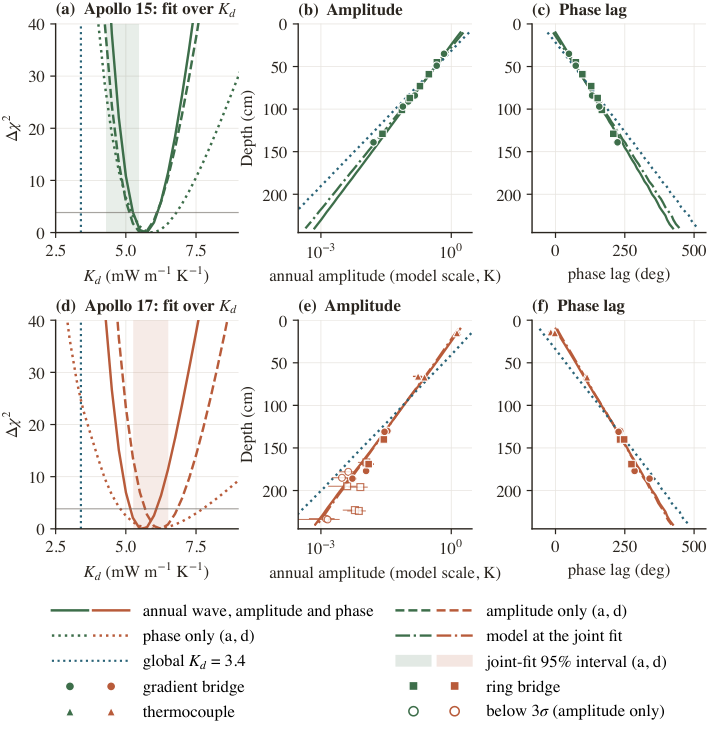

In [18]:
nb.show("fig_joint_annual_wave")

**SI Figure S6** (the posterior) and **SI Figure S7** ($K_d$ from every variant).

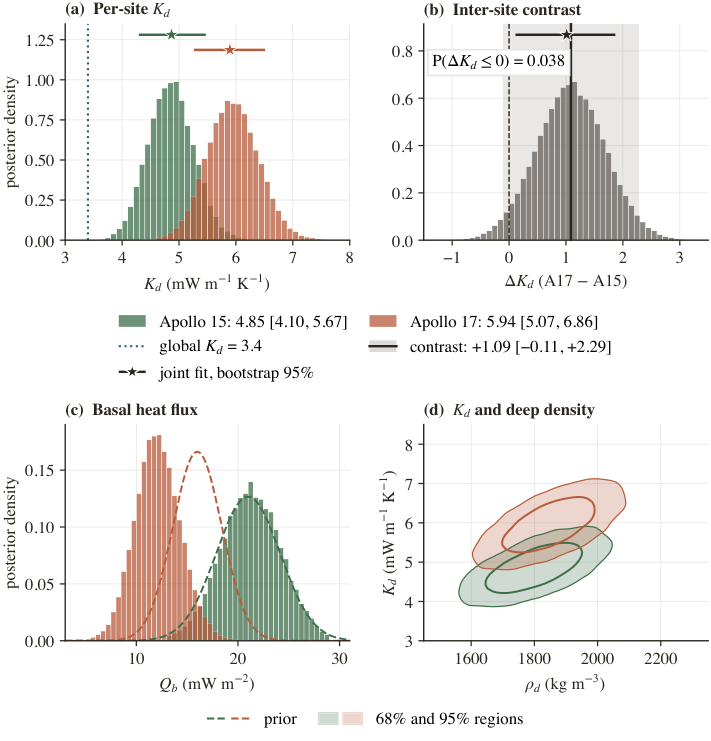

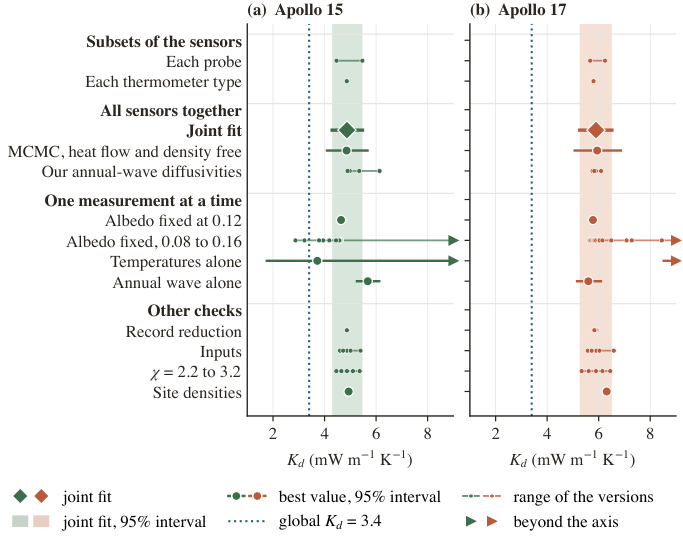

In [19]:
for f in ("fig_joint_mcmc", "fig_joint_variants"):
    nb.show(f)

---
## Summary

In [20]:
ok = nb.summary()
print()
print("Every value matches the paper." if ok else "Some values differ from the paper: see the list above.")

848 values checked against the paper in 14 tables: 848 match, 0 differ.

Every value matches the paper.
